# Connection Collective: Event Analysis, Part 3
### Stress-testing the food finding and turning the analysis into planning numbers

**Where Part 2 left us.** Among in-person events, none of 9 no-food events reached 10+ attendees vs 16 of 29 with food (Fisher p = 0.005). But I flagged that food is tangled up with other things: evening timing, the program's early period, and off-campus locations.

**Questions for this notebook**
1. **Confounding:** does the food association survive once we compare like with like (same era, same time of day, same event type)?
2. **Effect size & uncertainty:** with 0 of 9 in one group, what range of effects is actually plausible? (Frequentist, penalized, and Bayesian views.)
3. **Count model:** modeling the attendance *number* rather than a high/low flag, adjusting for several factors at once.
4. **Calendar:** does position in the term (exam season) matter?
5. **Planning:** what attendance should we expect for a given event design, and how should caps be set?
6. **Next experiment:** how many events would it take to settle the food question properly?
7. **Robustness & the remaining threads:** leave-out checks, themes in the Leads' notes, and Chill Spaces on its own terms.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, matplotlib.dates as mdates, seaborn as sns
from scipy import stats
from scipy.special import expit
import statsmodels.api as sm, statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 60)
rng = np.random.default_rng(2026)
GREEN, RED, BLUE = '#55A868', '#C44E52', '#4C72B0'

raw = pd.read_excel('/mnt/project/connection_collective_event_data.xlsx', sheet_name='Sheet2')
cc = raw[raw['Program']=='Connection Collective'].copy()
core = cc[cc['Series']!='Chill Spaces'].copy()                  # Chill Spaces handled separately (section 10)
att = core[core['Number_Attendees'].notna()].copy()
assert att['Date'].notna().all()

HIGH_CUT = 10                                                    # same definition as Part 2 (above the median of 9)
att['High'] = (att['Number_Attendees'] >= HIGH_CUT).astype(int)
att['Term'] = att['Semester'] + ' ' + att['Year'].astype(str)

# ---- engineered features ----
att['Early']   = (att['Date'] < '2025-06-01').astype(int)         # Oct 2023 – May 2025 vs Jul 2025 onward
att['Evening'] = att['Time'].map({'evening':1,'afternoon':0,'morning':0})   # NaN where time unknown
att['Creative']= (att['Type_event']=='creative').astype(int)
att['OffCampus'] = (att['Location'].fillna('').str.contains('Architecture') |
                    att['Attendance_Factors'].fillna('').str.contains('off-campus', case=False)).astype(int)
att['Food_Yes'] = att['Food_YN'].map({'Yes':1,'No':0})            # NaN where unknown

# approximate term calendar (start / end) used for 'week of term' — an assumption, +/- ~1 week
starts = {'Fall':(9,5), 'Winter':(1,6), 'Spring':(5,5)}; ends = {'Fall':(12,19), 'Winter':(4,24), 'Spring':(8,22)}
att['TermStart'] = [pd.Timestamp(int(y), *starts[s]) for y,s in zip(att['Year'], att['Semester'])]
att['TermEnd']   = [pd.Timestamp(int(y), *ends[s])   for y,s in zip(att['Year'], att['Semester'])]
att['Week'] = ((att['Date']-att['TermStart']).dt.days//7 + 1).clip(lower=1)
att['DaysToEnd'] = (att['TermEnd']-att['Date']).dt.days
att['LateTerm'] = (att['DaysToEnd'] <= 35).astype(int)

ip  = att[att['Modality']=='In Person'].copy()                    # in-person, non-Chill-Spaces
ipf = ip[ip['Food_Yes'].notna()].copy()                           # + food known  (Part 2's test set)
print(f"In-person events with attendance: {len(ip)} | with food known: {len(ipf)} "
      f"(food {int(ipf.Food_Yes.sum())}, no food {int((1-ipf.Food_Yes).sum())})")

In-person events with attendance: 41 | with food known: 38 (food 29, no food 9)


## 1. Is food just a proxy for *when* the event happened?

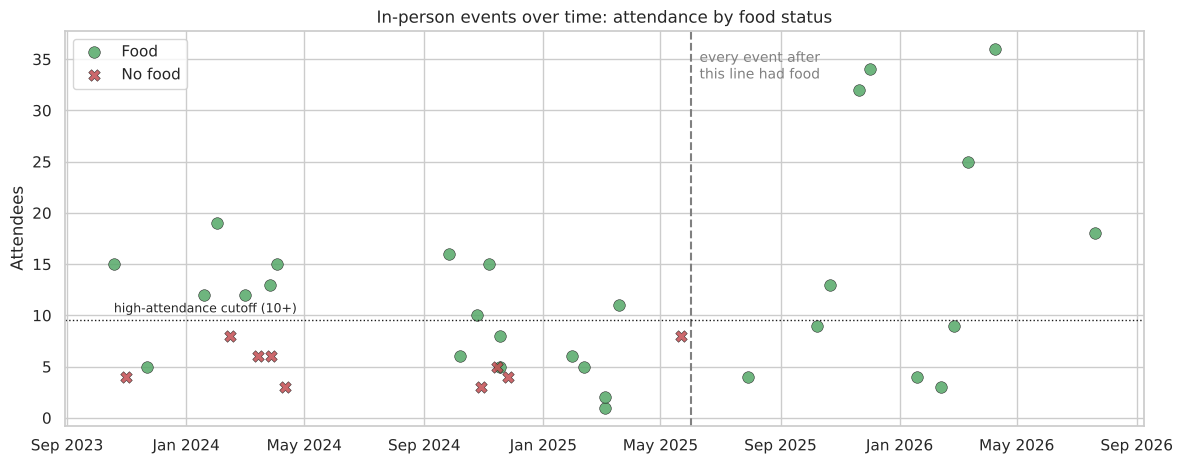

Food × era (in-person, food known):


Food_YN,No,Yes,All
Early,,,
Early (to May 2025),9,18,27
Recent (Jul 2025+),0,11,11
All,9,29,38


Food × time of day:


Food_YN,No,Yes,All
Evening,,,
afternoon,2,16,18
evening,7,12,19
All,9,28,37


Food × event type:


Food_YN,No,Yes,All
Type_event,,,
creative,6,14,20
discussion,3,3,6
food,0,1,1
party,0,10,10
study,0,1,1
All,9,29,38


In [2]:
fig, ax = plt.subplots(figsize=(12,4.8))
for f,(lab,col,mk) in {1:('Food',GREEN,'o'), 0:('No food',RED,'X')}.items():
    s = ipf[ipf['Food_Yes']==f]; ax.scatter(s['Date'], s['Number_Attendees'], c=col, s=70, marker=mk, label=lab, alpha=.85, edgecolor='k', linewidth=.4)
ax.axvline(pd.Timestamp('2025-06-01'), color='gray', ls='--'); ax.text(pd.Timestamp('2025-06-10'), ipf['Number_Attendees'].max()*.92, 'every event after\nthis line had food', fontsize=10, color='gray')
ax.axhline(HIGH_CUT-0.5, color='k', ls=':', lw=1); ax.text(ipf['Date'].min(), HIGH_CUT+0.3, f'high-attendance cutoff ({HIGH_CUT}+)', fontsize=9)
ax.set(title='In-person events over time: attendance by food status', ylabel='Attendees'); ax.legend(loc='upper left')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y')); plt.tight_layout(); plt.show()

print('Food × era (in-person, food known):'); display(pd.crosstab(ipf['Early'].map({1:'Early (to May 2025)',0:'Recent (Jul 2025+)'}), ipf['Food_YN'], margins=True))
tt = ipf.dropna(subset=['Evening']).copy()
print('Food × time of day:'); display(pd.crosstab(tt['Evening'].map({1:'evening',0:'afternoon'}), tt['Food_YN'], margins=True))
print('Food × event type:'); display(pd.crosstab(ipf['Type_event'], ipf['Food_YN'], margins=True))

**What the timeline shows**
- **Every no-food in-person event happened between Oct 2023 and May 2025. Every one of the 11 events since July 2025 had food.** That is the single most important caveat on the Part 2 result: food and program era travel together.
- Food is also unevenly spread across other features. 7 of the 9 no-food events were evening events, all 9 were creative or discussion events, and parties always had food.
- The silver lining: the groups **overlap enough to compare like with like**. The early era has 18 food vs 9 no-food events, evenings have 12 vs 7, and creative events have 14 vs 6. The recent era (11 vs 0) cannot be tested at all, which is a real limit on what this data can ever tell us.

## 2. Comparing like with like: stratified tests
If food were only standing in for era or time of day, the association should vanish *within* a stratum. Each row below is a smaller, fairer comparison. Small cells mean low power, so I'm looking at the **direction and size** of each gap as much as the p-value, and I apply a **Holm correction** because I'm running several tests.

,n_food,n_nofood,high_food,high_nofood,pct_food,pct_nofood,p_fisher,p_holm
subset,,,,,,,,
All in-person (baseline),29,9,16/29,0/9,0.552,0.0,0.005,0.029
Early era only (Oct 2023 – May 2025),18,9,10/18,0/9,0.556,0.0,0.009,0.044
Evening events only,12,7,5/12,0/7,0.417,0.0,0.106,0.212
Afternoon events only,16,2,10/16,0/2,0.625,0.0,0.183,0.212
Creative events only,14,6,8/14,0/6,0.571,0.0,0.042,0.135
Early era + evening,9,7,5/9,0/7,0.556,0.0,0.034,0.135
Recent era only (Jul 2025+),11,0,6/11,-,0.545,NaN,NaN,NaN


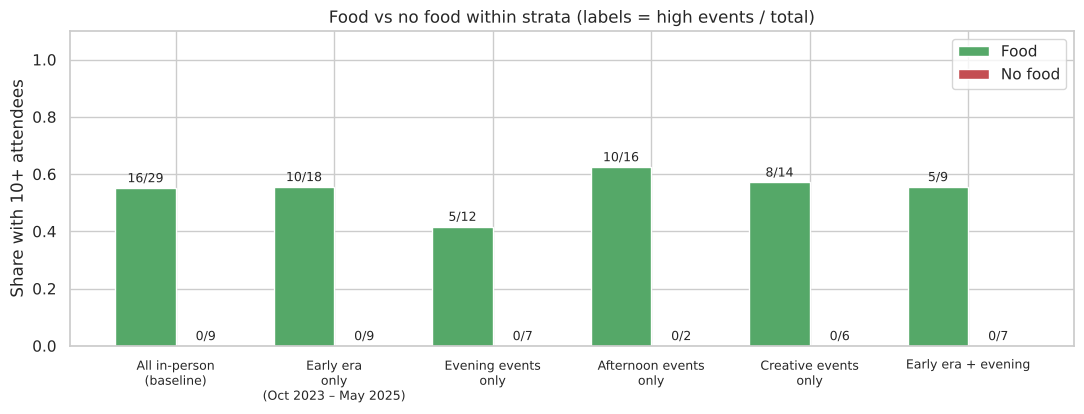

In [3]:
def food_row(d, label):
    g = d.groupby('Food_Yes')['High'].agg(['sum','count'])
    a,n1 = (g.loc[1,'sum'], g.loc[1,'count']) if 1 in g.index else (0,0)
    c,n0 = (g.loc[0,'sum'], g.loc[0,'count']) if 0 in g.index else (0,0)
    p = stats.fisher_exact([[a,n1-a],[c,n0-c]])[1] if (n1>0 and n0>0) else np.nan
    return dict(subset=label, n_food=int(n1), n_nofood=int(n0),
                high_food=f"{int(a)}/{int(n1)}" if n1 else '-', high_nofood=f"{int(c)}/{int(n0)}" if n0 else '-',
                pct_food=a/n1 if n1 else np.nan, pct_nofood=c/n0 if n0 else np.nan, p_fisher=p)

tt = ipf.dropna(subset=['Evening'])
strata = [('All in-person (baseline)', ipf),
          ('Early era only (Oct 2023 – May 2025)', ipf[ipf['Early']==1]),
          ('Evening events only', tt[tt['Evening']==1]),
          ('Afternoon events only', tt[tt['Evening']==0]),
          ('Creative events only', ipf[ipf['Creative']==1]),
          ('Early era + evening', tt[(tt['Early']==1)&(tt['Evening']==1)]),
          ('Recent era only (Jul 2025+)', ipf[ipf['Early']==0])]
res = pd.DataFrame([food_row(d,l) for l,d in strata])
ok = res['p_fisher'].notna()
res.loc[ok,'p_holm'] = multipletests(res.loc[ok,'p_fisher'], method='holm')[1]
display(res.round(3).set_index('subset'))

# visual: share high, food vs no food, by stratum
plot = res[res['n_nofood']>0].copy(); x = np.arange(len(plot)); w=.38
fig, ax = plt.subplots(figsize=(11,4.3))
ax.bar(x-w/2, plot['pct_food'], w, color=GREEN, label='Food'); ax.bar(x+w/2, plot['pct_nofood'], w, color=RED, label='No food')
for i,(_,r) in enumerate(plot.iterrows()):
    ax.text(i-w/2, r['pct_food']+.02, r['high_food'], ha='center', fontsize=9); ax.text(i+w/2, r['pct_nofood']+.02, r['high_nofood'], ha='center', fontsize=9)
ax.set_xticks(x); ax.set_xticklabels([s.replace(' (','\n(').replace(' only','\nonly') for s in plot['subset']], fontsize=9)
ax.set(ylim=(0,1.1), ylabel=f'Share with {HIGH_CUT}+ attendees', title='Food vs no food within strata (labels = high events / total)'); ax.legend(); plt.tight_layout(); plt.show()

In [4]:
# Adjusted test: shuffle the food label *within* strata of (era × time of day), so the comparison is always like-for-like.
d = tt.copy(); d['stratum'] = d['Early'].astype(str)+'|'+d['Evening'].astype(int).astype(str)
food = d['Food_Yes'].to_numpy(); high = d['High'].to_numpy(); strat = d['stratum'].to_numpy()
idx_by = {s: np.where(strat==s)[0] for s in np.unique(strat)}
def stat_fn(f): return sum(high[i][f[i]==1].sum() for i in idx_by.values())   # high events among food events, summed over strata
obs = stat_fn(food)
perm = []
for _ in range(10000):
    f = food.copy()
    for i in idx_by.values(): f[i] = rng.permutation(f[i])
    perm.append(stat_fn(f))
perm = np.array(perm); exp_ = perm.mean()
p_adj = (np.abs(perm-exp_) >= abs(obs-exp_)-1e-9).mean()
print(f"Strata used: {sorted(idx_by)}  (n = {len(d)})")
print(f"High events among food events: observed {obs}, expected under 'food doesn't matter' {exp_:.1f}")
print(f"Stratified permutation p-value (adjusted for era × time of day): {p_adj:.4f}")

# cross-check: Cochran–Mantel–Haenszel
from statsmodels.stats.contingency_tables import StratifiedTable
tabs=[]
for s,i in idx_by.items():
    sub=d.iloc[i]; a=((sub.Food_Yes==1)&(sub.High==1)).sum(); b=((sub.Food_Yes==1)&(sub.High==0)).sum()
    c=((sub.Food_Yes==0)&(sub.High==1)).sum(); e=((sub.Food_Yes==0)&(sub.High==0)).sum()
    if (a+b)>0 and (c+e)>0: tabs.append(np.array([[a,b],[c,e]])+0.0)
st = StratifiedTable(tabs); print(f"CMH test of null odds ratio = 1 (strata with both groups: {len(tabs)}): p = {st.test_null_odds(correction=True).pvalue:.4f}")

Strata used: ['0|0', '0|1', '1|0', '1|1']  (n = 37)
High events among food events: observed 15, expected under 'food doesn't matter' 11.9
Stratified permutation p-value (adjusted for era × time of day): 0.0099
CMH test of null odds ratio = 1 (strata with both groups: 2): p = 0.0254


**Result: the association survives comparing like with like.**
- **Early era only (18 food vs 9 no-food):** 10 of 18 food events reached high attendance vs 0 of 9 (p = 0.009; Holm-adjusted 0.044). So the effect isn't just "recent events are bigger and happen to have food."
- **Within other strata** the picture is the same direction every time: evening only 5/12 vs 0/7 (p = 0.106), creative only 8/14 vs 0/6 (p = 0.042), early era + evening 5/9 vs 0/7 (p = 0.034). In every stratum, no no-food event reached high attendance, while 42% to 63% of food events did.
- **After Holm correction for running several tests, only the baseline and the early-era test stay below 0.05.** The smaller subgroups (2 to 7 no-food events) don't have the power to clear that bar on their own, which is a power limit rather than a contradiction.
- **Adjusted tests that handle era and time of day together** agree: stratified permutation p = 0.0099 and Cochran–Mantel–Haenszel p = 0.025 (only 2 strata have both food groups, so the CMH test has limited information).

Bottom line: adjusting for era and time of day does not make the association go away.

## 3. Effect size under separation: Firth logistic regression and a Bayesian view
With 0 of 9 no-food events reaching high attendance, an ordinary logistic regression has an infinite coefficient (complete separation). Two standard remedies:
- **Firth's penalized likelihood**, which gives finite, less biased estimates and works with a covariate-adjusted model.
- **A Bayesian Beta-Binomial model**, which reports the plausible *range* of each group's high-attendance rate directly. I show a flat prior and a **skeptical prior** that pulls both groups toward the overall rate, to guard against over-reading a result found after looking at the data (the winner's curse).

In [5]:
def firth_logit(X, y, max_iter=300, tol=1e-9):
    X=np.asarray(X,float); y=np.asarray(y,float); b=np.zeros(X.shape[1])
    for _ in range(max_iter):
        p=expit(X@b); W=p*(1-p); I=X.T@(X*W[:,None]); Iinv=np.linalg.inv(I)
        h=W*np.einsum('ij,jk,ik->i',X,Iinv,X); U=X.T@(y-p+h*(0.5-p)); step=Iinv@U
        m=np.abs(step).max()
        if m>5: step*=5/m
        b=b+step
        if np.abs(step).max()<tol: break
    p=expit(X@b); W=p*(1-p); I=X.T@(X*W[:,None])
    ll=np.sum(y*np.log(p)+(1-y)*np.log(1-p))+0.5*np.log(np.linalg.det(I))
    return b, np.linalg.inv(I), ll

def firth_table(d, cols):
    X = np.column_stack([np.ones(len(d))]+[d[c].to_numpy(float) for c in cols]); y=d['High'].to_numpy()
    b,cov,ll = firth_logit(X,y); se=np.sqrt(np.diag(cov)); rows=[]
    for j,c in enumerate(cols, start=1):
        _,_,ll0 = firth_logit(np.delete(X,j,axis=1), y); lr=2*(ll-ll0)
        rows.append(dict(term=c, odds_ratio=np.exp(b[j]), lo95=np.exp(b[j]-1.96*se[j]), hi95=np.exp(b[j]+1.96*se[j]), LR_p=stats.chi2.sf(lr,1)))
    return pd.DataFrame(rows).set_index('term')

fm = tt.copy()
print(f"Firth logistic regression, high attendance (n = {len(fm)}). Odds ratios; Wald CI; penalized-likelihood-ratio p.\n")
print('Model A: Food + Evening + Early era'); display(firth_table(fm, ['Food_Yes','Evening','Early']).round(3))
print('Model B: + Creative event type');     display(firth_table(fm, ['Food_Yes','Evening','Early','Creative']).round(3))

Firth logistic regression, high attendance (n = 37). Odds ratios; Wald CI; penalized-likelihood-ratio p.

Model A: Food + Evening + Early era


,odds_ratio,lo95,hi95,LR_p
term,,,,
Food_Yes,19.044,0.850,426.872,0.008
Evening,0.435,0.095,1.990,0.181
Early,1.457,0.289,7.352,0.428


Model B: + Creative event type


,odds_ratio,lo95,hi95,LR_p
term,,,,
Food_Yes,19.239,0.888,416.609,0.008
Evening,0.455,0.099,2.086,0.196
Early,1.545,0.284,8.407,0.433
Creative,1.297,0.276,6.102,0.440


,food: P(high),no food: P(high),difference (95% CrI),P(food better),P(gap > 20 pts)
model,,,,,
"Flat prior, all in-person",55% (37%–72%),9% (0%–31%),46 pts (19 to 67),0.999,0.972
"Skeptical prior, all in-person",52% (37%–68%),20% (5%–41%),33 pts (6 to 55),0.991,0.843
"Skeptical prior, early era only",51% (33%–70%),20% (5%–41%),32 pts (4 to 56),0.986,0.808


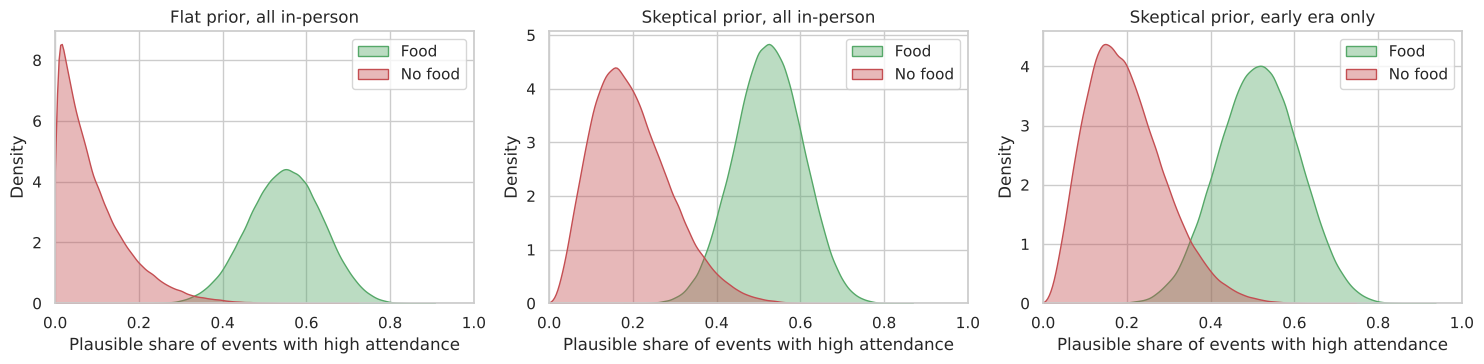

In [6]:
def post(a, n, prior=(1,1), size=200000): return rng.beta(a+prior[0], n-a+prior[1], size)
g = ipf.groupby('Food_Yes')['High'].agg(['sum','count']); a1,n1 = int(g.loc[1,'sum']), int(g.loc[1,'count']); a0,n0 = int(g.loc[0,'sum']), int(g.loc[0,'count'])
early = ipf[ipf['Early']==1].groupby('Food_Yes')['High'].agg(['sum','count']); e1,m1 = int(early.loc[1,'sum']), int(early.loc[1,'count']); e0,m0 = int(early.loc[0,'sum']), int(early.loc[0,'count'])
base = ipf['High'].mean(); skeptic = (base*8, (1-base)*8)          # worth 8 'pseudo-events', centered on the overall rate for BOTH groups
setups = {'Flat prior, all in-person':(a1,n1,a0,n0,(1,1)), 'Skeptical prior, all in-person':(a1,n1,a0,n0,skeptic), 'Skeptical prior, early era only':(e1,m1,e0,m0,skeptic)}
rows=[]; draws={}
for name,(x1,k1,x0,k0,pr) in setups.items():
    pf, pn = post(x1,k1,pr), post(x0,k0,pr); diff = pf-pn; draws[name]=(pf,pn,diff)
    rows.append({'model':name,'food: P(high)':f"{pf.mean():.0%} ({np.percentile(pf,2.5):.0%}–{np.percentile(pf,97.5):.0%})",
                 'no food: P(high)':f"{pn.mean():.0%} ({np.percentile(pn,2.5):.0%}–{np.percentile(pn,97.5):.0%})",
                 'difference (95% CrI)':f"{diff.mean()*100:.0f} pts ({np.percentile(diff,2.5)*100:.0f} to {np.percentile(diff,97.5)*100:.0f})",
                 'P(food better)':(diff>0).mean(), 'P(gap > 20 pts)':(diff>.2).mean()})
display(pd.DataFrame(rows).set_index('model').round(3))

fig, ax = plt.subplots(1,3, figsize=(15,3.8), sharey=False)
for a_,(name,(pf,pn,diff)) in zip(ax, draws.items()):
    sns.kdeplot(pf, ax=a_, color=GREEN, fill=True, alpha=.4, label='Food'); sns.kdeplot(pn, ax=a_, color=RED, fill=True, alpha=.4, label='No food')
    a_.set(title=name, xlabel='Plausible share of events with high attendance', xlim=(0,1)); a_.legend()
plt.tight_layout(); plt.show()

**How large is the effect, really?**
- **Firth regression:** food has a penalized-likelihood-ratio p = 0.008 in both models (with and without event type), so the association holds after adjusting for evening, early era, and creative type. The odds ratio itself (about 19) comes with a huge Wald interval (0.85 to 427). Under separation, Wald intervals are unreliable and the point estimate is not trustworthy, so **I would not quote "19 times" anywhere**. Evening (OR 0.44), early era (1.46), and creative (1.30) are all non-significant (LR p between 0.18 and 0.44).
- **Bayesian view:** the plausible no-food high-attendance rate is about 9% (0% to 31%) under a flat prior and 20% (5% to 41%) under the skeptical prior, versus roughly 52% to 55% for food events.
- **The gap:** best-guess about 46 points under the flat prior and **about 33 points (6 to 55) under the skeptical prior**; restricting to the early era gives 32 points (4 to 56). The probability that food events are better is at least 98.6% in all three setups, and the probability that the gap exceeds 20 points is 81% to 97%.

In plain terms: I'm confident food events do better; I'm not confident how much better. A fair summary is "somewhere between a few points and over fifty, most likely around 30."

## 4. A count model for attendance
Instead of collapsing attendance into high/low, model the **number** of attendees. Counts like these are overdispersed (variance far above the mean), so I use a **negative binomial regression** and check that Poisson is inadequate. Coefficients are reported as **incidence-rate ratios** (IRR): 1.5 means "50% more attendees, holding the other factors constant." Because events within a term share a calendar and a Leads team, I also compute a **cluster bootstrap by term** for the food effect.

In [7]:
md_ = tt.copy(); md_['Food_Yes']=md_['Food_Yes'].astype(int); md_['Evening']=md_['Evening'].astype(int)
F1 = 'Number_Attendees ~ Food_Yes + Evening + Early'
pois = smf.glm(F1, data=md_, family=sm.families.Poisson()).fit()
print(f"Poisson Pearson dispersion = {pois.pearson_chi2/pois.df_resid:.2f}  (1.0 would mean Poisson is adequate; >> 1 means overdispersed)")
nbm = smf.negativebinomial(F1, data=md_).fit(disp=0, maxiter=500)
ci = np.exp(nbm.conf_int()); tab = pd.DataFrame({'IRR':np.exp(nbm.params),'lo95':ci[0],'hi95':ci[1],'p':nbm.pvalues}).drop(['Intercept','alpha'])
print(f"Negative binomial (n = {len(md_)}), dispersion alpha = {nbm.params['alpha']:.2f}"); display(tab.round(3))

# cluster bootstrap by term
terms = md_['Term'].unique(); boots=[]; n_try=0
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    for _ in range(400):
        pick = rng.choice(terms, len(terms), replace=True); s = pd.concat([md_[md_['Term']==t] for t in pick])
        if s['Food_Yes'].nunique()<2: continue
        n_try += 1
        try: boots.append(np.exp(smf.negativebinomial(F1, data=s).fit(disp=0, maxiter=200).params['Food_Yes']))
        except Exception: pass
boots=np.array(boots); boots=boots[np.isfinite(boots)&(boots<50)]
print(f"\nCluster bootstrap by term ({len(terms)} terms; {len(boots)} of {n_try} resamples converged): food IRR median {np.median(boots):.2f}, 95% interval {np.percentile(boots,2.5):.2f}–{np.percentile(boots,97.5):.2f}")
print(f"Share of resamples where food IRR > 1: {(boots>1).mean():.0%}")

Poisson Pearson dispersion = 3.99  (1.0 would mean Poisson is adequate; >> 1 means overdispersed)
Negative binomial (n = 37), dispersion alpha = 0.27


,IRR,lo95,hi95,p
Food_Yes,1.673,0.976,2.868,0.061
Evening,0.665,0.426,1.037,0.072
Early,0.669,0.413,1.083,0.102



Cluster bootstrap by term (7 terms; 390 of 398 resamples converged): food IRR median 1.78, 95% interval 0.90–2.30
Share of resamples where food IRR > 1: 97%


Leave-one-out mean absolute error:  model = 6.1 attendees   |   'always guess the median' = 6.1


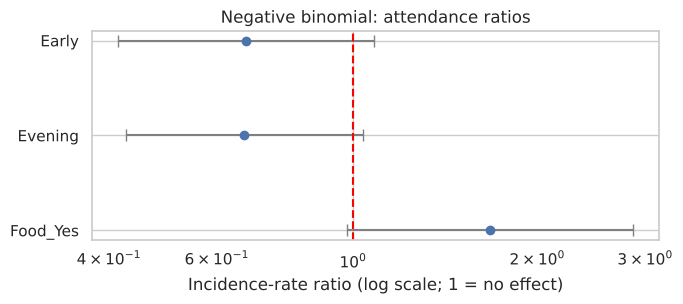

In [8]:
# does the model predict better than a naive guess? leave-one-out
errs=[]; base_errs=[]
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    for i in range(len(md_)):
        tr = md_.drop(md_.index[i]); te = md_.iloc[[i]]
        try:
            m_ = smf.negativebinomial(F1, data=tr).fit(disp=0, maxiter=300); pred = float(m_.predict(te).iloc[0])
        except Exception: pred = tr['Number_Attendees'].mean()
        errs.append(abs(pred-te['Number_Attendees'].iloc[0])); base_errs.append(abs(tr['Number_Attendees'].median()-te['Number_Attendees'].iloc[0]))
print(f"Leave-one-out mean absolute error:  model = {np.mean(errs):.1f} attendees   |   'always guess the median' = {np.mean(base_errs):.1f}")

fig, ax = plt.subplots(figsize=(7,3.2)); t = tab.reset_index()
ax.errorbar(t['IRR'], range(len(t)), xerr=[t['IRR']-t['lo95'], t['hi95']-t['IRR']], fmt='o', color=BLUE, ecolor='gray', capsize=4)
ax.axvline(1, color='red', ls='--'); ax.set_yticks(range(len(t))); ax.set_yticklabels(t['index']); ax.set_xscale('log')
ax.set(xlabel='Incidence-rate ratio (log scale; 1 = no effect)', title='Negative binomial: attendance ratios'); plt.tight_layout(); plt.show()

**Modeling the attendance count**
- Poisson is inadequate (dispersion 4.0), so the negative binomial is the right tool (dispersion 0.27).
- **Food IRR = 1.67 (95% CI 0.98 to 2.87, p = 0.061):** holding evening and era fixed, food events drew about 70% more attendees. Evening (IRR 0.67, p = 0.07) and early era (0.67, p = 0.10) each point to roughly a third fewer attendees but are not individually significant.
- **Cluster bootstrap by term** gives a median of 1.78 and a 95% interval of 0.90 to 2.30; the food IRR exceeds 1 in 97% of resamples. With only 7 terms as clusters, treat these intervals as rough.
- **This evidence is weaker than the high/low test.** The Fisher test is powered by the zero cell (0 of 9). The count model uses every attendance number, and it says "probably positive, plausibly 1.3× to 2×, can't rule out no effect."
- **Predictive check:** leave-one-out error is 6.1 attendees for the model and 6.1 for "always guess the median." The model helps explain associations but **does not predict individual events better than a simple guess**, so use it for understanding, not forecasting one event.

## 5. Calendar effects: where in the term does an event fall?
I derived **week of term** and **days until term end** from approximate term dates (Fall starts ~Sep 5, Winter ~Jan 6, Spring ~May 5; term ends ~Dec 19, Apr 24, Aug 22). These are **my assumptions** (off by up to about a week), so treat the findings as directional. 'Late term' = the last 5 weeks, which includes exams.

By phase of term:


,events,median,mean
Phase,,,
Weeks 1–4,6,10.0,10.8
Weeks 5–9,15,8.0,7.7
Week 10+,17,8.0,13.5


Late term (last 5 weeks) vs not:


,events,median,mean
LateTerm,,,
0,23,8.0,9.2
1,15,8.0,13.3


Spearman correlation, week of term vs attendance: rho = 0.04, p = 0.80


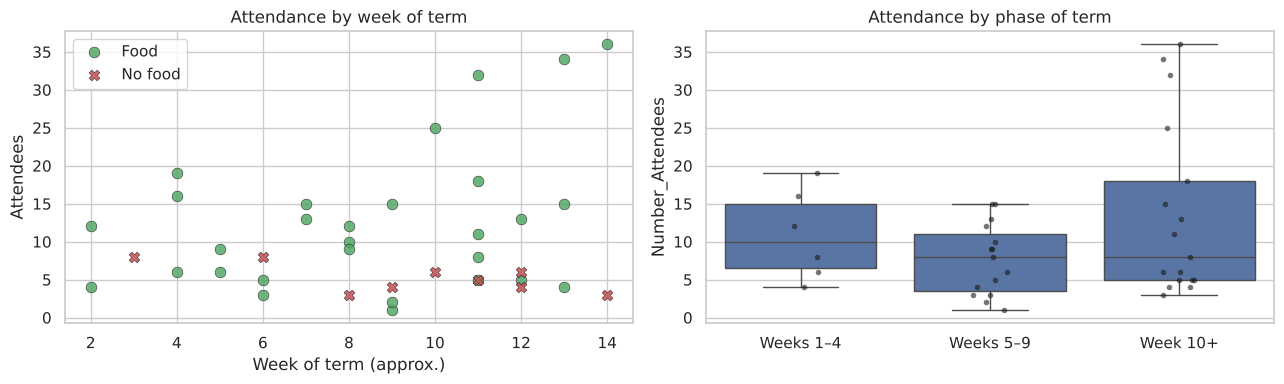

Negative binomial with late-term added:


,IRR,lo95,hi95,p
Food_Yes,1.706,1.002,2.902,0.049
Evening,0.668,0.433,1.030,0.068
Early,0.702,0.436,1.129,0.144
LateTerm,1.256,0.839,1.882,0.268


In [9]:
cal = ipf.copy()
cal['Phase'] = pd.cut(cal['Week'], [0,4,9,99], labels=['Weeks 1–4','Weeks 5–9','Week 10+'])
print('By phase of term:'); display(cal.groupby('Phase')['Number_Attendees'].agg(events='count', median='median', mean='mean').round(1))
print('Late term (last 5 weeks) vs not:'); display(cal.groupby('LateTerm')['Number_Attendees'].agg(events='count', median='median', mean='mean').round(1))
rho,p = stats.spearmanr(cal['Week'], cal['Number_Attendees']); print(f"Spearman correlation, week of term vs attendance: rho = {rho:.2f}, p = {p:.2f}")

fig, ax = plt.subplots(1,2, figsize=(13,4))
for f,(lab,col,mk) in {1:('Food',GREEN,'o'),0:('No food',RED,'X')}.items():
    s=cal[cal['Food_Yes']==f]; ax[0].scatter(s['Week'], s['Number_Attendees'], c=col, s=60, marker=mk, label=lab, edgecolor='k', linewidth=.4, alpha=.85)
ax[0].set(xlabel='Week of term (approx.)', ylabel='Attendees', title='Attendance by week of term'); ax[0].legend()
sns.boxplot(data=cal, x='Phase', y='Number_Attendees', color=BLUE, showfliers=False, ax=ax[1]); sns.stripplot(data=cal, x='Phase', y='Number_Attendees', color='k', size=4, alpha=.6, ax=ax[1])
ax[1].set(title='Attendance by phase of term', xlabel='')
plt.tight_layout(); plt.show()

mc = tt.copy(); mc['Food_Yes']=mc['Food_Yes'].astype(int); mc['Evening']=mc['Evening'].astype(int)
m2 = smf.negativebinomial('Number_Attendees ~ Food_Yes + Evening + Early + LateTerm', data=mc).fit(disp=0, maxiter=500)
c2 = np.exp(m2.conf_int()); print('Negative binomial with late-term added:'); display(pd.DataFrame({'IRR':np.exp(m2.params),'lo95':c2[0],'hi95':c2[1],'p':m2.pvalues}).drop(['Intercept','alpha']).round(3))

**Calendar effects**
- **No evidence that position in the term matters.** Week of term vs attendance has a Spearman correlation of 0.04 (p = 0.80); medians by phase are 10, 8, and 8.
- Late-term events (last 5 weeks, including exams) have the same median (8) but a higher mean (13.3 vs 9.2). The mean is pulled up by three large events: the Gingerbread Hangout, the Self-Care Bag, and Canvas Collective. In the count model, late term has an IRR of 1.26 (p = 0.27), and the food estimate barely moves (1.71, p = 0.049).
- Takeaway: exam season doesn't sink well-designed events. The Leads' exam-season warnings apply to specific formats (study sessions, co-working), and take-home items before exams appear to have done well. The term dates here are my approximations, so treat this as directional.

## 6. Planning numbers: expected attendance and cap-setting
Using the negative binomial model, I simulate the **predictive distribution** of attendance for a few realistic event designs (recent era). From that I read off a typical turnout, an 80% range, the chance of reaching high attendance, and a **cap** that would turn away people only about 10% of the time. Then I audit how current caps compare with actual turnout.

**Caution:** no-food events have not been run since mid-2025, so the 'no food, recent' scenarios are extrapolations from the older data.

,expected mean,median,80% range,P(10+ attendees),cap with ~10% turn-away risk
design,,,,,
Afternoon + food,17.95,16.0,7–32,0.79,32
Evening + food,11.93,11.0,4–21,0.57,21
"Afternoon, no food*",10.73,10.0,3–19,0.51,19
"Evening, no food*",7.13,6.0,2–13,0.26,13


* extrapolation: no no-food events have run since May 2025

Sanity check: what actually happened in each design cell (all eras, in-person)?


,events,median,mean,p90,max
design,,,,,
food / afternoon,16,12.5,15.4,33.0,36.0
food / evening,12,7.5,8.2,15.0,15.0
no food / afternoon,2,5.5,5.5,5.9,6.0
no food / evening,7,4.0,5.1,8.0,8.0


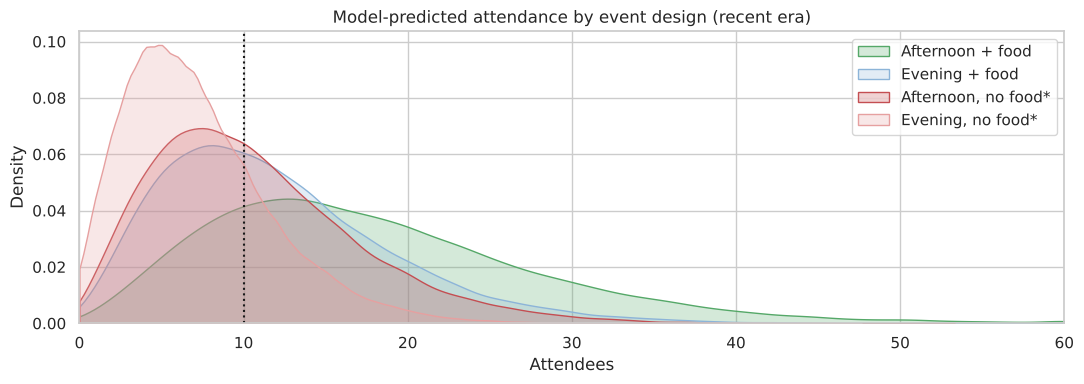

In [10]:
alpha = nbm.params['alpha']; r = 1/alpha
def sim(mu, n=40000): return rng.negative_binomial(r, r/(r+mu), n)
scen = pd.DataFrame({'Food_Yes':[1,1,0,0],'Evening':[0,1,0,1],'Early':[0,0,0,0]}, index=['Afternoon + food','Evening + food','Afternoon, no food*','Evening, no food*'])
mu = nbm.predict(scen); rows=[]; samples={}
for name in scen.index:
    s = sim(mu[name]); samples[name]=s
    rows.append({'design':name,'expected mean':mu[name],'median':np.median(s),'80% range':f"{np.percentile(s,10):.0f}–{np.percentile(s,90):.0f}",
                 f'P({HIGH_CUT}+ attendees)':(s>=HIGH_CUT).mean(),'cap with ~10% turn-away risk':int(np.ceil(np.percentile(s,90)))})
display(pd.DataFrame(rows).set_index('design').round(2)); print('* extrapolation: no no-food events have run since May 2025')

print('\nSanity check: what actually happened in each design cell (all eras, in-person)?')
emp = tt.copy(); emp['design'] = np.where(emp['Food_Yes']==1,'food','no food')+' / '+np.where(emp['Evening']==1,'evening','afternoon')
display(emp.groupby('design')['Number_Attendees'].agg(events='count', median='median', mean='mean', p90=lambda s: s.quantile(.9), max='max').round(1))

fig, ax = plt.subplots(figsize=(11,4))
for name,col in zip(scen.index,[GREEN,'#8CB4D8',RED,'#E6A0A0']): sns.kdeplot(np.clip(samples[name],0,60), ax=ax, label=name, color=col, fill=True, alpha=.25, clip=(0,60))
ax.axvline(HIGH_CUT, color='k', ls=':'); ax.set(title='Model-predicted attendance by event design (recent era)', xlabel='Attendees', xlim=(0,60)); ax.legend(); plt.tight_layout(); plt.show()

Capped in-person events: 32
  at/over cap: 3  |  fill < 50%: 15  |  cap at least 2× turnout: 18  |  cap at least 3× turnout: 12


,events,median_cap,median_turnout,median_fill,at_cap
Series,,,,,
Collaboration,2,20.0,3.5,0.18,0
Collective Chill,22,18.0,10.5,0.64,3
Conversations,4,35.0,7.0,0.20,0
Social,3,17.0,15.0,0.75,0
Special Event,1,15.0,3.0,0.20,0


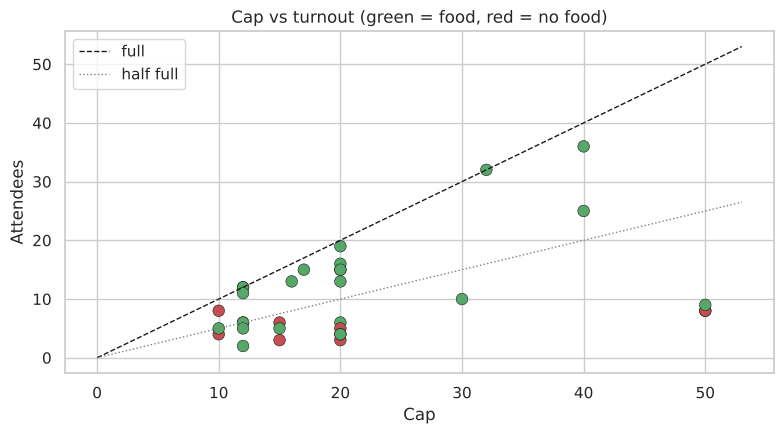

In [11]:
# how do actual caps compare with turnout? (in-person, capped, attendance known)
capd = ip.dropna(subset=['Limit']).copy(); capd['Fill']=capd['Number_Attendees']/capd['Limit']; capd['CapRatio']=capd['Limit']/capd['Number_Attendees']
print(f"Capped in-person events: {len(capd)}")
print(f"  at/over cap: {int((capd.Fill>=1).sum())}  |  fill < 50%: {int((capd.Fill<.5).sum())}  |  cap at least 2× turnout: {int((capd.CapRatio>=2).sum())}  |  cap at least 3× turnout: {int((capd.CapRatio>=3).sum())}")
byser = capd.groupby('Series').agg(events=('Fill','count'), median_cap=('Limit','median'), median_turnout=('Number_Attendees','median'), median_fill=('Fill','median'), at_cap=('Fill', lambda s:(s>=1).sum())).round(2)
display(byser)
fig, ax = plt.subplots(figsize=(8,4.5)); sc=ax.scatter(capd['Limit'], capd['Number_Attendees'], c=capd['Food_Yes'].map({1:GREEN,0:RED}), s=70, edgecolor='k', linewidth=.4)
lim=capd['Limit'].max()+3; ax.plot([0,lim],[0,lim],'k--',lw=1,label='full'); ax.plot([0,lim],[0,lim/2],'gray',ls=':',lw=1,label='half full')
ax.set(xlabel='Cap', ylabel='Attendees', title='Cap vs turnout (green = food, red = no food)'); ax.legend(); plt.tight_layout(); plt.show()

**Planning numbers**
- **Model-based expectations (recent era):** an afternoon event with food averages about 18 attendees (80% range 7 to 32; 79% chance of 10+), an evening event with food about 12 (4 to 21; 57%). The no-food designs (about 11 and 7) are extrapolations.
- **What actually happened (all eras):** afternoon with food had a median of 12.5 (p90 = 33), evening with food 7.5, and no-food events 5.5 (afternoon, 2 events) and 4 (evening, 7 events). The model runs higher than history because it is for the recent era, when events were larger.
- Given the predictive check above, these are **rough planning ranges, not forecasts**. The consistent message is that afternoon with food is the strongest design and the uncertainty is wide (a single afternoon food event can plausibly land anywhere from 7 to 32).
- **Cap audit:** of 32 capped in-person events, only 3 hit their cap, 15 were under half full, and 18 had a cap at least double turnout. By series, Collective Chill caps (median 18) roughly match turnout (median 10.5, 64% full), but **Conversations (median cap 35 vs turnout 7) and Collaboration (20 vs 3.5) are heavily over-capped**. The flip side: the biggest afternoon food events filled (Gingerbread 32/32 with a waitlist; Canvas 36/40), so those may deserve higher caps.

## 7. Designing the experiment that would settle it
The observational data can't separate food from everything it travels with, so the right next step is a **randomized comparison**. How big does it need to be? I compute **exact power** for Fisher's test, assuming food events reach high attendance 55% of the time (as observed) and testing a range of true no-food rates. I plan around **smaller effects than the raw data suggests** because the observed gap was found after the fact and is likely to be inflated. I also compute power for a **matched-pairs design** (two comparable events per pair, one with food and one without, assigned by coin flip), which controls for type and timing by construction.

Events needed PER ARM for 80% power (unpaired, Fisher exact, α = 0.05):


,events per arm
Large gap (no food = 10%),19
Moderate gap (no food = 25%),>40
Modest gap (no food = 35%),>40


,Large gap (no food = 10%),Moderate gap (no food = 25%),Modest gap (no food = 35%)
events per arm,,,
8,0.30,0.13,0.06
10,0.38,0.13,0.05
15,0.64,0.23,0.10
20,0.84,0.38,0.15
30,0.96,0.57,0.26
40,0.99,0.73,0.37


Matched PAIRS needed for 80% power (each pair = 2 events), assuming independence within pairs (conservative):


,pairs
Large gap (no food = 10%),21
Moderate gap (no food = 25%),>40
Modest gap (no food = 35%),>40


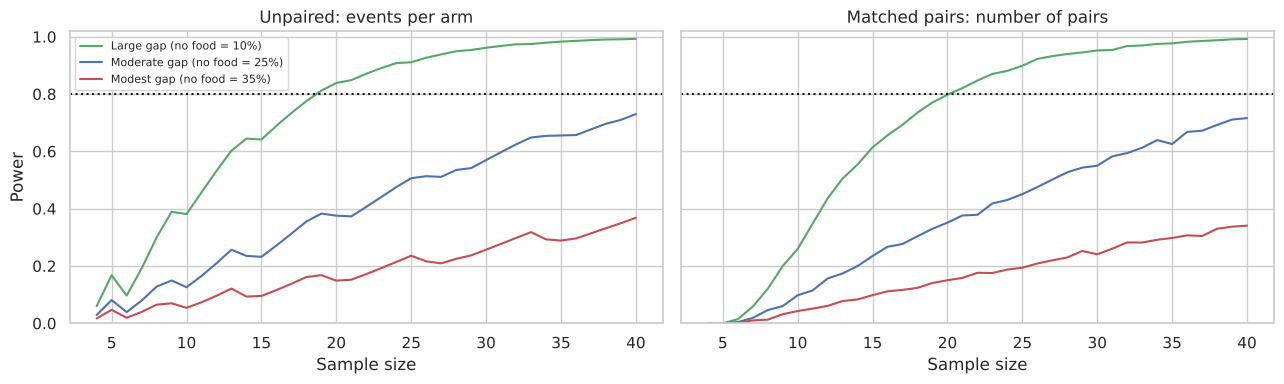

In [12]:
from scipy.stats import binom
NS = range(4, 41); p1 = 0.55
pv_tables = {}
for n in NS:
    a = np.arange(n+1); pv_tables[n] = np.array([[stats.fisher_exact([[x,n-x],[y,n-y]])[1] for y in a] for x in a])
def power_unpaired(p1,p0,n):
    a=np.arange(n+1); return float((binom.pmf(a,n,p1)[:,None]*binom.pmf(a,n,p0)[None,:]*(pv_tables[n]<=.05)).sum())

scen_p0 = {'Large gap (no food = 10%)':.10, 'Moderate gap (no food = 25%)':.25, 'Modest gap (no food = 35%)':.35}
pw = pd.DataFrame({k:[power_unpaired(p1,v,n) for n in NS] for k,v in scen_p0.items()}, index=list(NS))
need = {k:(pw.index[pw[k]>=.8][0] if (pw[k]>=.8).any() else '>40') for k in pw}
print('Events needed PER ARM for 80% power (unpaired, Fisher exact, α = 0.05):'); display(pd.Series(need, name='events per arm').to_frame())
display(pw.loc[[8,10,15,20,30,40]].round(2).rename_axis('events per arm'))

# paired design (exact McNemar-type sign test on discordant pairs), simulated
KS = range(4, 41); pvd = np.ones((41,41))
for d_ in range(0,41):
    for x in range(0,d_+1): pvd[d_,x] = stats.binomtest(x, d_, .5).pvalue if d_>0 else 1.0
def power_paired(p1,p0,k,sims=4000):
    q10=p1*(1-p0); q01=p0*(1-p1); cnt=rng.multinomial(k,[q10,q01,1-q10-q01],size=sims); d_=cnt[:,0]+cnt[:,1]
    return float((pvd[d_,cnt[:,0]]<=.05).mean())
pwp = pd.DataFrame({k:[power_paired(p1,v,n) for n in KS] for k,v in scen_p0.items()}, index=list(KS))
needp = {k:(pwp.index[pwp[k]>=.8][0] if (pwp[k]>=.8).any() else '>40') for k in pwp}
print('Matched PAIRS needed for 80% power (each pair = 2 events), assuming independence within pairs (conservative):'); display(pd.Series(needp, name='pairs').to_frame())

fig, ax = plt.subplots(1,2, figsize=(13,4), sharey=True)
for k,col in zip(pw.columns,[GREEN,BLUE,RED]):
    ax[0].plot(pw.index, pw[k], color=col, label=k); ax[1].plot(pwp.index, pwp[k], color=col, label=k)
for a_,t in zip(ax,['Unpaired: events per arm','Matched pairs: number of pairs']): a_.axhline(.8,color='k',ls=':'); a_.set(title=t, xlabel='Sample size', ylim=(0,1.02))
ax[0].set_ylabel('Power'); ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

**Power with a high/low outcome**
- With a 55% high-attendance rate for food events, detecting a **large** gap (no food = 10%) takes about **19 events per arm** (21 matched pairs).
- A **moderate** gap (no food = 25%) isn't reachable even at 40 per arm (73% power), and a **modest** gap (35%) is far out of reach.
- Because the observed gap was found after looking, the true gap is probably smaller than the raw data suggests, so planning around the moderate case is the honest choice. That means dichotomizing attendance into high/low wastes information.

Power to detect a food effect on the attendance COUNT (rank tests, α = 0.05); n = events per arm / number of pairs:


,"unpaired, IRR=1.3","unpaired, IRR=1.7","unpaired, IRR=2.0","paired, IRR=1.3","paired, IRR=1.7","paired, IRR=2.0"
n,,,,,,
6,0.08,0.19,0.35,0.05,0.11,0.20
10,0.16,0.39,0.61,0.13,0.36,0.58
14,0.14,0.55,0.80,0.14,0.55,0.80
18,0.20,0.65,0.85,0.19,0.65,0.85
22,0.25,0.77,0.94,0.25,0.74,0.94
26,0.28,0.81,0.96,0.28,0.82,0.96
30,0.35,0.85,0.98,0.33,0.87,0.98
34,0.39,0.90,0.99,0.40,0.91,0.99
38,0.42,0.95,1.00,0.43,0.95,1.00


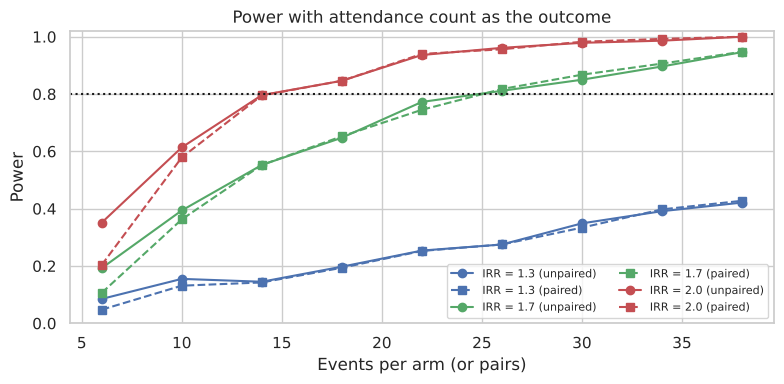

In [13]:
# Power when the OUTCOME IS THE ATTENDANCE COUNT (no dichotomizing). Counts drawn from the fitted negative binomial.
r_ = 1/nbm.params['alpha']; MU0 = 7        # no-food mean attendance assumed ~7
def draw(mu, size): return rng.negative_binomial(r_, r_/(r_+mu), size)
def power_counts(irr, n, sims=800):
    hit_u=hit_p=0
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        for _ in range(sims):
            a = draw(MU0*irr, n); b = draw(MU0, n)
            hit_u += stats.mannwhitneyu(a, b, alternative='two-sided').pvalue < .05
            try: hit_p += stats.wilcoxon(a, b).pvalue < .05
            except ValueError: pass
    return hit_u/sims, hit_p/sims
sizes = list(range(6, 41, 4)); rows=[]
for irr in [1.3, 1.7, 2.0]:
    for n in sizes:
        u,p = power_counts(irr, n); rows.append(dict(IRR=irr, n=n, unpaired=u, paired=p))
pc = pd.DataFrame(rows)
piv = pc.pivot(index='n', columns='IRR', values='unpaired').round(2); piv.columns=[f'unpaired, IRR={c}' for c in piv.columns]
pv2 = pc.pivot(index='n', columns='IRR', values='paired').round(2); pv2.columns=[f'paired, IRR={c}' for c in pv2.columns]
print('Power to detect a food effect on the attendance COUNT (rank tests, α = 0.05); n = events per arm / number of pairs:')
display(pd.concat([piv, pv2], axis=1).rename_axis('n'))
fig, ax = plt.subplots(figsize=(8,4))
for irr,col in zip([1.3,1.7,2.0],[BLUE,GREEN,RED]):
    d_=pc[pc['IRR']==irr]; ax.plot(d_['n'], d_['unpaired'], color=col, marker='o', label=f'IRR = {irr} (unpaired)'); ax.plot(d_['n'], d_['paired'], color=col, ls='--', marker='s', label=f'IRR = {irr} (paired)')
ax.axhline(.8, color='k', ls=':'); ax.set(xlabel='Events per arm (or pairs)', ylabel='Power', title='Power with attendance count as the outcome', ylim=(0,1.02)); ax.legend(fontsize=8, ncol=2); plt.tight_layout(); plt.show()

**Power with attendance count as the outcome**
- Using the full count is much more efficient. A **2× effect needs about 14 events per arm** for 80% power, and a **1.7× effect needs about 26 per arm** (roughly 52 events in total). A 1.3× effect is not detectable at realistic sizes (only 42% power at 38 per arm).
- The paired and unpaired versions come out nearly equal here because I assumed independence within pairs (the conservative case); real matching on type and timing should do somewhat better.
- **Practical implication:** at the current pace of roughly 2 to 5 qualifying events per term, even the optimistic case takes years. A formal experiment is the cleanest answer but a slow one, which is why the dashboard-based approach (record every event, update the estimate each term) is likely more realistic, ideally alternating food and no-food on comparable events where Leads are willing.

## 8. Robustness: does the food result survive leave-outs?
A result worth acting on should not hinge on a handful of events or on events with data-quality questions. Each row re-runs the in-person food comparison after dropping a group of events. Rows where one group is empty cannot be tested.

,n_food,n_nofood,high_food,high_nofood,pct_food,pct_nofood,p_fisher,p_holm,gap_pts
subset,,,,,,,,,
Baseline: all in-person,29,9,16/29,0/9,0.552,0.0,0.005,0.034,55.172
Drop events with data-quality flags,27,8,16/27,0/8,0.593,0.0,0.004,0.030,59.259
Drop off-campus events,29,7,16/29,0/7,0.552,0.0,0.011,0.044,55.172
Drop the 3 biggest events (30+),26,9,13/26,0/9,0.500,0.0,0.013,0.044,50.000
Drop 2023 events,27,8,15/27,0/8,0.556,0.0,0.006,0.034,55.556
Drop Winter 2024 (densest early term),24,5,11/24,0/5,0.458,0.0,0.126,0.126,45.833
Drop discussion events,26,6,16/26,0/6,0.615,0.0,0.018,0.044,61.538
Early era only,18,9,10/18,0/9,0.556,0.0,0.009,0.044,55.556
Recent era only,11,0,6/11,-,0.545,NaN,NaN,NaN,NaN


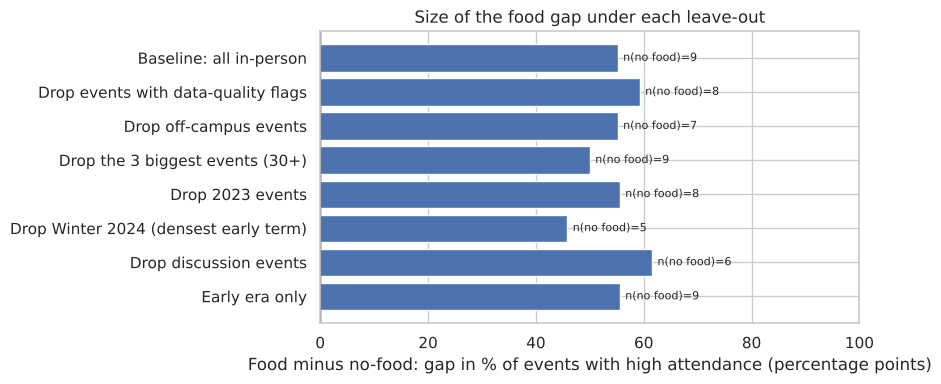

In [14]:
flag_names = 'Storytelling|Self-Love Soiree|Black History Month Jeopardy'      # events with data-quality notes in the source
rob = [('Baseline: all in-person', ipf),
       ('Drop events with data-quality flags', ipf[~ipf['Event_Name'].str.contains(flag_names)]),
       ('Drop off-campus events', ipf[ipf['OffCampus']==0]),
       ('Drop the 3 biggest events (30+)', ipf[ipf['Number_Attendees']<30]),
       ('Drop 2023 events', ipf[ipf['Date']>='2024-01-01']),
       ('Drop Winter 2024 (densest early term)', ipf[~((ipf['Year']==2024)&(ipf['Semester']=='Winter'))]),
       ('Drop discussion events', ipf[ipf['Type_event']!='discussion']),
       ('Early era only', ipf[ipf['Early']==1]),
       ('Recent era only', ipf[ipf['Early']==0])]
rb = pd.DataFrame([food_row(d,l) for l,d in rob]); ok = rb['p_fisher'].notna()
rb.loc[ok,'p_holm'] = multipletests(rb.loc[ok,'p_fisher'], method='holm')[1]
rb['gap_pts'] = (rb['pct_food']-rb['pct_nofood'])*100
display(rb.round(3).set_index('subset'))

p_ = rb[ok].copy(); fig, ax = plt.subplots(figsize=(9,4))
ax.barh(p_['subset'], p_['gap_pts'], color=BLUE); ax.invert_yaxis(); ax.axvline(0,color='k',lw=1)
for i,(g_,n_) in enumerate(zip(p_['gap_pts'], p_['n_nofood'])): ax.text(g_+1, i, f"n(no food)={n_}", va='center', fontsize=8)
ax.set(xlabel='Food minus no-food: gap in % of events with high attendance (percentage points)', title='Size of the food gap under each leave-out', xlim=(0,100)); plt.tight_layout(); plt.show()

**Robustness**
- **The food gap survives every leave-out where testing is possible**, ranging from 46 to 62 points. Dropping events with data-quality flags, off-campus events, 2023 events, the three biggest events, or the discussion events all leave p-values between 0.004 and 0.018, and every one of those stays below 0.05 after Holm correction.
- **The one place it weakens is dropping Winter 2024** (p = 0.126, Holm 0.126). That removes 4 of the 9 no-food events (leaving 5), so the loss of power matters more than the gap, which is still 46 points with 0 of 5 no-food events high. It is a power drop, not a reversal.
- Caveat: these subsets overlap heavily, so they aren't independent tests and the correction is approximate. The result also still rests on a small group of no-food events. Even so, the pattern doesn't hinge on any one data-quality issue or any single big event.

## 9. What do the Leads' notes say? (theme coding)
I coded the free-text columns (Notes, Reflection_Summary, Attendance_Factors) for recurring themes and compared median attendance for in-person events that mention a theme vs those that don't. Caveat: these notes were written *after* the event with the result known, so they explain outcomes rather than predict them.

In [15]:
txt = (ip['Notes'].fillna('')+' '+ip['Reflection_Summary'].fillna('')+' '+ip['Attendance_Factors'].fillna('')).str.lower()
themes = {'Promotion / posters / registration':r'promot|poster|registrat|uwaterloolife','Location problem (off-campus / hard to find / commute)':r'off-campus|commute|hard to find',
          'Exam / midterm season':r'exam|midterm','Weather / air quality':r'weather|snow|smoke|air quality','Repeat / returning attendees':r'repeat|returning|familiar|consistent',
          'Waitlist / at capacity':r'waitlist|at capacity','Care kits / take-home items':r'care kit|care package|self-care|goodie|take-home','Hybrid component':r'hybrid'}
rows=[]
for k,pat in themes.items():
    m = txt.str.contains(pat, regex=True)
    rows.append({'theme':k,'events mentioning':int(m.sum()),'median (mentioned)':ip.loc[m,'Number_Attendees'].median(),'median (not mentioned)':ip.loc[~m,'Number_Attendees'].median()})
th = pd.DataFrame(rows).set_index('theme').round(1); display(th)

,events mentioning,median (mentioned),median (not mentioned)
theme,,,
Promotion / posters / registration,3,9.0,8.0
Location problem (off-campus / hard to find / commute),3,3.0,9.0
Exam / midterm season,4,7.5,8.0
Weather / air quality,1,4.0,8.5
Repeat / returning attendees,2,7.5,8.0
Waitlist / at capacity,3,12.0,8.0
Care kits / take-home items,6,6.5,9.0
Hybrid component,0,NaN,8.0


**What the Leads' notes say** (small counts, so descriptive only)
- **Location problems** (off-campus, hard to find, commute) show up in 3 events, with a median attendance of 3 vs 9 for the rest.
- **Waitlist or at-capacity** mentions (3 events) have a median of 12 vs 8.
- **Care kits and take-home items** (6 events) have a median of 6.5 vs 9: a mix of the biggest and the smallest events, so no clean message.
- Exam or midterm mentions (7.5 vs 8), promotion mentions (9 vs 8), and the single weather and two repeat-attendee mentions show no clear pattern.

## 10. Chill Spaces on its own terms
Chill Spaces is a drop-in, so headcount per session isn't the right yardstick. More relevant: is it **consistent**, and does it **hold up through exam season** (when it was deliberately offered as a co-working format)?

Chill Spaces sessions: 22 | with attendance recorded: 17 | no attendance recorded: 5


,value
median per session,6.00
mean,5.90
min,1.00
max,10.00
sessions with 1 attendee,3.00
sessions with 5+,12.00
coefficient of variation,0.52


,sessions,median,min,max
Month,,,,
2026-05,1,1.0,1.0,1.0
2026-06,4,9.5,6.0,10.0
2026-07,4,5.0,4.0,7.0
2026-08,3,1.0,1.0,5.0
2026-09,3,9.0,8.0,9.0
2026-10,2,5.5,4.0,7.0


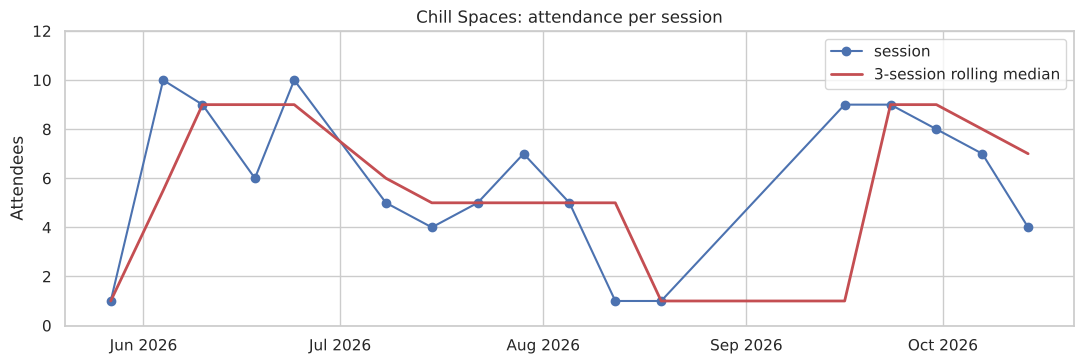

In [16]:
cs = cc[cc['Series']=='Chill Spaces'].copy(); csa = cs[cs['Number_Attendees'].notna()].sort_values('Date')
print(f"Chill Spaces sessions: {len(cs)} | with attendance recorded: {len(csa)} | no attendance recorded: {len(cs)-len(csa)}")
s = csa['Number_Attendees']
display(pd.Series({'median per session':s.median(),'mean':round(s.mean(),1),'min':s.min(),'max':s.max(),
    'sessions with 1 attendee':int((s==1).sum()),'sessions with 5+':int((s>=5).sum()),'coefficient of variation':round(s.std()/s.mean(),2)}).to_frame('value'))
csa['Month'] = csa['Date'].dt.to_period('M').astype(str)
display(csa.groupby('Month')['Number_Attendees'].agg(sessions='count', median='median', min='min', max='max'))
fig, ax = plt.subplots(figsize=(11,3.8))
ax.plot(csa['Date'], csa['Number_Attendees'], marker='o', color=BLUE, label='session'); ax.plot(csa['Date'], csa['Number_Attendees'].rolling(3, min_periods=1).median(), color=RED, lw=2, label='3-session rolling median')
ax.set(title='Chill Spaces: attendance per session', ylabel='Attendees', ylim=(0, max(s)+2)); ax.legend(); ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y')); plt.tight_layout(); plt.show()

**Chill Spaces on its own terms**
- Of 22 sessions, 17 have attendance recorded. The median is 6 (range 1 to 10), 12 of the 17 sessions had 5 or more people, and 3 had a single attendee.
- It looks like a **steady small group with dips**, not a failure. Monthly medians run 9.5 in June, 5 in July, 9 in September, and 5.5 in October, but the mid-August sessions with a single attendee carry notes about exam season and few people on campus.
- The right yardstick is retention, such as whether the same students return week to week. This data can't show that because it only records headcount.

## 11. Synthesis: what I'd now tell the Leads

**What I'm confident about**
- **Food events do better.** The association holds after adjusting for era and time of day, holds within the early era, and survives every leave-out except one that simply removes too many no-food events. No no-food in-person event ever reached 10 attendees.
- **Afternoon beats evening, and creative/party events in Collective Chill are the strongest designs.**
- **Caps for Conversations and Collaboration events have been far too high**, while the biggest afternoon food events are the ones that fill.

**What I'm only moderately sure about**
- **How much food matters.** Plausibly a 1.3× to 2× boost in attendance, or about 30 points more chance of reaching 10+ (wide range, roughly 5 to 55). The count model alone can't fully rule out no effect.
- **Whether food causes it.** No-food events were all from the early program, none have run since mid-2025, and Leads chose when to serve food. The remaining confound I can't test is that the early events differed in ways I haven't recorded (promotion, audience, team).

**What I can't say**
- Anything about no-food events in the recent era (there are none), who attends, or whether people return.
- Anything about week-of-term effects with confidence; I found nothing, but the dates are approximations and n is small.

**Recommended next steps**
1. **Keep food as the default for creative and party events.** It is a cheap choice, and the evidence leans in its favor.
2. **Run a deliberate alternation** on comparable events (same type and time slot) when Leads are willing, and record every outcome. Even a few pairs would start to address the remaining confound.
3. **Update the estimate each term** using the Bayesian approach here. The dashboard can track the food gap with its uncertainty so the answer sharpens as events accumulate.
4. **Right-size caps:** around 10 to 15 for Conversations and Collaboration, and higher (30 to 40) for large afternoon creative events.
5. **Fix the data gaps:** record registrations, audience type, food, and time for every event (especially the 2026 headcount-log rows), and note any promotion effort.
6. **Don't forecast single events from the model.** It does not beat a median guess, so use its ranges only for rough planning.

**Limits of this whole analysis.** About 40 in-person events, observational data, several tests run, and approximate term dates. Treat the p-values as evidence strength, not as proof.